# Linear Regression

In [2]:
import numpy as np
import matplotlib.pyplot as plt

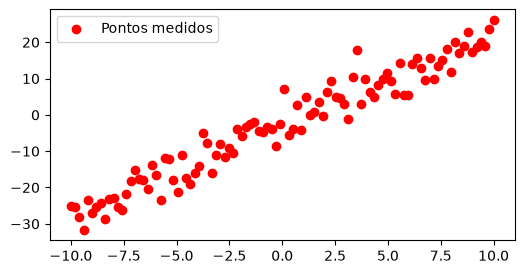

In [19]:
# comecamos com a, b
a_real = 2.5
b_real = -3.2

n = 100 # numero de medicoes
x_medido = np.linspace(-10,10,n).reshape( (n,1) )

# fenomeno medido
y_real = a_real * x_medido + b_real

# aplicando erro na distribuicao de pontos
alpha = 4
phi = np.random.normal(size=(n,1))
y_medido = y_real + alpha * phi

plt.figure(figsize=(6,3))
plt.scatter(x_medido, y_medido, c='r', label='Pontos medidos')
plt.legend()
plt.show()

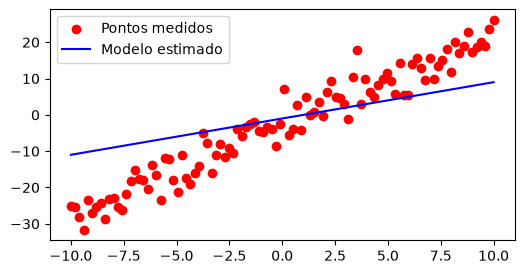

In [20]:
# vamos "chutar" um modelo estimado:
a_estimado = 1.0
b_estimado = -1.0

# com os parametros estimados do modelo, criamos saidas estimadas:
y_estimado = x_medido * a_estimado + b_estimado

plt.figure(figsize=(6,3))
plt.scatter(x_medido, y_medido, c='r', label='Pontos medidos')
plt.plot(x_medido, y_estimado, c='b', label='Modelo estimado')
plt.legend()
plt.show()

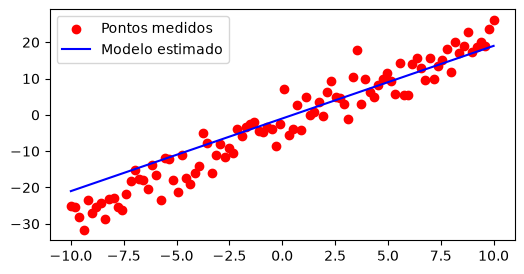

In [21]:
# vamos "chutar" um modelo estimado:
a_estimado = 2.0
b_estimado = -1.0

# com os parametros estimados do modelo, criamos saidas estimadas:
y_estimado = x_medido * a_estimado + b_estimado

plt.figure(figsize=(6,3))
plt.scatter(x_medido, y_medido, c='r', label='Pontos medidos')
plt.plot(x_medido, y_estimado, c='b', label='Modelo estimado')
plt.legend()
plt.show()

## Pseudoinversa

Trazendo para matrizes, nossa estimativa sobre as medidas, temos $\begin{bmatrix} \hat{y}_1 \\ \hat{y}_2 \\ \vdots \\ \hat{y}_n \end{bmatrix} = \begin{bmatrix} x_1 & 1 \\ x_2 & 1 \\ \vdots & \vdots \\ x_n & 1 \end{bmatrix} \begin{bmatrix} a \\ b \end{bmatrix}$ que pode ser escrito como $\hat{y} = X w^T$

Se o modelo fosse perfeito, teríamos $y = X w^T$, e bastaria “inverter $X$”. Mas $X$ não é quadrada, então não tem inversa. Na prática, com muitos pontos e ruído, não existe reta que passe por todos. Então, a estratégia é multiplicar os dois lados por $X^T$ à esquerda:

$$X^T y = X^T X\, w^T$$

Agora $X^T X$ é quadrada. Atenção: ela é $2 \times 2$ (número de parâmetros × número de parâmetros), não $n \times n$ como está escrito na página. Se ela for inversível:

$$w^T = \underbrace{(X^T X)^{-1} X^T}_{X^+}\, y$$

A matriz $X^+ = (X^T X)^{-1}X^T$ é a $\textbf{pseudo-inversa}$ de $X$. Uma multiplicação de matrizes dá direto os melhores $a$ e $b$.

In [22]:
# colocando as estimativas na forma matricial 
X = np.hstack ( (x_medido, np.ones_like(x_medido)) )
pinvX = np.linalg.inv( X.T @ X ) @ X.T
wT = pinvX @ y_medido

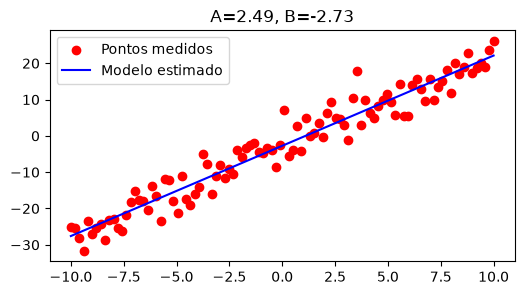

In [23]:
# com os parametros estimados do modelo, criamos saidas estimadas:
a_estimado = wT[0,0]
b_estimado = wT[1,0]
y_estimado = a_estimado * x_medido + b_estimado

plt.figure(figsize=(6,3))
plt.scatter(x_medido, y_medido, c='r', label='Pontos medidos')
plt.plot(x_medido, y_estimado, c='b', label='Modelo estimado')
plt.title(f'A={a_estimado:.2f}, B={b_estimado:.2f}')
plt.legend()
plt.show()

### Mas porque isso minimiza o erro?

<img src="projecao_minimos_quadrados.png" width="900">

Chame de $\hat{y}$ o ponto do plano tal que $e = y - \hat{y}$ é perpendicular ao plano. Pegue qualquer outro ponto $p$ do plano. Então

$$y - p = \underbrace{(y - \hat{y})}_{e} + (\hat{y} - p)$$

O vetor $\hat{y} - p$ está dentro do plano, porque é a diferença de dois pontos do plano, e $e$ é perpendicular ao plano. Os dois formam um ângulo reto, e Pitágoras dá:

$$\|y - p\|^2 = \|e\|^2 + \|\hat{y} - p\|^2 \;\geq\; \|e\|^2$$

Qualquer outro ponto tem erro igual a $\|e\|^2$ mais um termo não negativo. Logo $\hat{y}$ tem o menor erro possível, e ele é único: a igualdade só vale quando $p = \hat{y}$.

Substituindo $e = y - Xw^T$:

$$X^T(y - Xw^T) = 0 \;\;\Longrightarrow\;\; X^T X\, w^T = X^T y \;\;\Longrightarrow\;\; w^T = (X^T X)^{-1} X^T y$$